# Лабораторная работа № 3
## Классификация изображений отходов

Кононенко С. В., группа 4332. Вариант 6. Используется [Kaggle Garbage Classification](https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification), фотографии которого совпадают с оригинальным TrashNet. Шесть классов — cardboard, glass, metal, paper, plastic и trash.

Сравниваются собственная CNN, MobileNetV2 и классификатор на основе предобученного автоэнкодера. Лимиты эпох увеличены втрое относительно первоначального запуска. У модели на основе автоэнкодера после обучения головы выполняется совместное обучение энкодера и головы по меткам классов.

Запускайте ячейки сверху вниз из корня репозитория. Python 3.12, зависимости в `lr3/requirements.txt`, входные данные и ImageNet-веса в `lr3/data`.

[Исходная работа](https://github.com/imnoname/intelligent-data-analysis-ml/tree/7e6e317b572f07a853dc55797137338c3160d83f/lr3).


## 1 Среда и параметры обучения

В первой ячейке `EPOCH_MULTIPLIER = 3` увеличивает исходные лимиты эпох и терпение ранней остановки втрое. Дополнительно задаётся 30 эпох совместного дообучения энкодера и классификатора. Фактическое число эпох и выбранная эпоха сохраняются в итоговую таблицу.

Ранняя остановка, уменьшение скорости обучения и контрольные точки соответствуют приёмам из «Лекции 2», слайды 43–48. Обучение прерывается, если ошибка на validation перестаёт уменьшаться. Число эпох является верхним пределом.


In [1]:
import os, random, sys, time, json
from datetime import datetime, timezone
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "6")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from hashlib import sha256, file_digest
from io import BytesIO
from PIL import Image, ImageOps
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
 precision_recall_fscore_support, confusion_matrix, log_loss, classification_report)
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")
SEED=42; random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
IMG_SIZE=(96,96); BATCH_SIZE=32; AUTOTUNE=tf.data.AUTOTUNE
EPOCH_MULTIPLIER = int(os.environ.get("LR3_EPOCH_MULTIPLIER", "3"))
if EPOCH_MULTIPLIER < 1:
    raise ValueError("EPOCH_MULTIPLIER должен быть положительным целым числом.")
sns.set_theme(style="whitegrid", palette=["#246759", "#b95a31"])
print("Python:", sys.version.split()[0], "| TensorFlow:", tf.__version__)
print("Устройства:", [d.device_type for d in tf.config.list_physical_devices()])
print("Размер изображения:",IMG_SIZE,"batch:",BATCH_SIZE,"seed:",SEED)
ARTIFACTS = Path("lr3/results")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
EPOCHS = {
    "cnn": 10 * EPOCH_MULTIPLIER,
    "mobile": 7 * EPOCH_MULTIPLIER,
    "autoencoder": 6 * EPOCH_MULTIPLIER,
    "head": 18 * EPOCH_MULTIPLIER,
    "ae_finetune": 10 * EPOCH_MULTIPLIER,
    "cnn_plain": 5 * EPOCH_MULTIPLIER,
    "mobile_finetune": 4 * EPOCH_MULTIPLIER,
}
RUN_STARTED = datetime.now(timezone.utc).isoformat()
RUN_TIMER = time.perf_counter()
print("Множитель исходных лимитов эпох:", EPOCH_MULTIPLIER)
display(pd.Series(EPOCHS, name="Максимум эпох").to_frame())


Python: 3.12.14 | TensorFlow: 2.21.0
Устройства: ['CPU']
Размер изображения: (96, 96) batch: 32 seed: 42
Множитель исходных лимитов эпох: 3


,Максимум эпох
cnn,30
mobile,21
autoencoder,18
head,54
ae_finetune,30
cnn_plain,15
mobile_finetune,12


In [2]:
DATASET_URL = "https://www.kaggle.com/api/v1/datasets/download/asdasdasasdas/garbage-classification"
ARCHIVE_SHA256 = "9d76dce1c47d23c92adc3d461d3ea6191070220e6238f9aa60c2ee61227ad88b"
KAGGLE_ROOT = "Garbage classification/Garbage classification"
DATA_DIR = Path("lr3/data")
if not DATA_DIR.is_dir() and Path("code-repository/lr3/data").is_dir():
    DATA_DIR = Path("code-repository/lr3/data")
BUNDLED_ARCHIVE = DATA_DIR / "trashnet.zip"
TRASHNET_SHA256 = "0bf472790f8b20e5c950d5b5012a9d38af0d3392efd65f8ce171334fc16b07c2"
ARCHIVE_ROOTS = {ARCHIVE_SHA256: KAGGLE_ROOT, TRASHNET_SHA256: "dataset-resized"}
class_names = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
NUM_CLASSES = len(class_names)
CLASS_TO_ID = {name: i for i, name in enumerate(class_names)}

def load_archive():
    local = os.environ.get("LR3_KAGGLE_ARCHIVE")
    if local or BUNDLED_ARCHIVE.is_file():
        archive = Path(local).expanduser() if local else BUNDLED_ARCHIVE
        with archive.open("rb") as stream:
            digest = file_digest(stream, "sha256").hexdigest()
        if digest not in ARCHIVE_ROOTS:
            raise ValueError("ZIP не совпадает с проверенным архивом TrashNet или Kaggle.")
        return archive, ARCHIVE_ROOTS[digest]
    archive = tf.keras.utils.get_file(
        "lr3-kaggle-garbage-9d76dce1.zip", origin=DATASET_URL,
        file_hash=ARCHIVE_SHA256, hash_algorithm="sha256", cache_subdir="datasets",
    )
    return Path(archive), KAGGLE_ROOT

def read_dataset(archive, archive_root):
    rows, images, broken = [], [], []
    with ZipFile(archive) as zf:
        members = sorted(n for n in zf.namelist()
                         if n.startswith(archive_root + "/")
                         and PurePosixPath(n).parent.name in CLASS_TO_ID
                         and PurePosixPath(n).suffix.lower() in {".jpg", ".jpeg", ".png"})
        for name in members:
            data = zf.read(name)
            cls = PurePosixPath(name).parent.name
            try:
                with Image.open(BytesIO(data)) as raw:
                    rgb = ImageOps.exif_transpose(raw).convert("RGB")
                    width, height = rgb.size
                    resized = rgb.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
                    pixels = np.asarray(resized, dtype=np.uint8)
            except (OSError, ValueError):
                broken.append(name)
                continue
            rows.append({"member": name, "class": cls, "label": CLASS_TO_ID[cls],
                         "digest": sha256(data).hexdigest(), "width": width, "height": height,
                         "image_id": len(images)})
            images.append(pixels)
    if not images:
        raise ValueError("В архиве нет изображений ожидаемой структуры.")
    valid = pd.DataFrame(rows)
    groups = valid.groupby("digest")["label"].nunique()
    ambiguous = groups[groups > 1].index
    unambiguous = valid.loc[~valid.digest.isin(ambiguous)]
    clean = unambiguous.drop_duplicates("digest").reset_index(drop=True)
    summary = {
        "файлов в одном дереве архива": len(members),
        "повреждённых файлов": len(broken),
        "копий с одинаковой меткой удалено": len(unambiguous) - len(clean),
        "файлов с противоречивой меткой удалено": len(valid) - len(unambiguous),
        "изображений после очистки": len(clean),
    }
    return clean, np.stack(images), summary


## 2 Загрузка и разведочный анализ

В репозитории лежит архив авторов TrashNet с 2 527 снимками. Архив Kaggle содержит два одинаковых дерева с разным регистром папок, поэтому при загрузке с Kaggle читается только одно. Метка определяется папкой. Перед разбиением исключаем повреждённые файлы и точные дубли по SHA-256. Хеш байтов не выявляет похожие или пересохранённые снимки.


,Количество
файлов в одном дереве архива,2527
повреждённых файлов,0
копий с одинаковой меткой удалено,0
файлов с противоречивой меткой удалено,6
изображений после очистки,2521


,Фотографий после очистки
class,
cardboard,403
glass,498
metal,409
paper,594
plastic,480
trash,137


,,Файлов
width,height,
512,384,2521


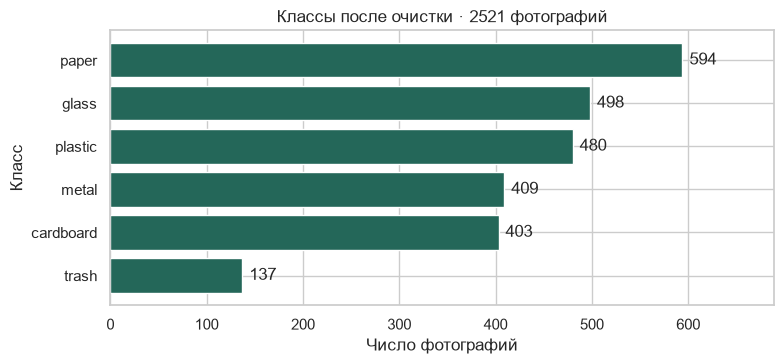

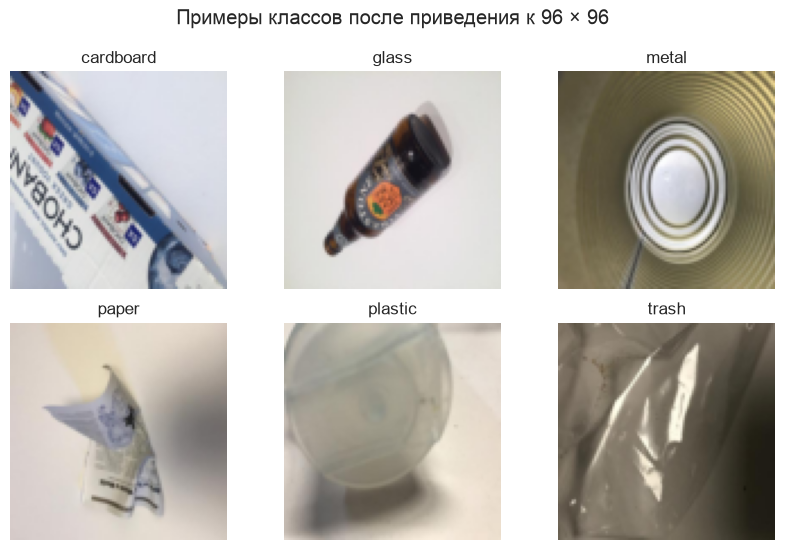

In [3]:
df, images, audit = read_dataset(*load_archive())
assert audit["файлов в одном дереве архива"] == 2527
assert set(df["class"]) == set(class_names)
assert df.digest.is_unique and df.member.is_unique
assert images.shape[1:] == (*IMG_SIZE, 3)
display(pd.Series(audit, name="Количество").to_frame())
counts = df["class"].value_counts().reindex(class_names)
display(counts.rename("Фотографий после очистки").to_frame())
display(df.groupby(["width", "height"]).size().nlargest(8).rename("Файлов").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
ordered = counts.sort_values()
bars = ax.barh(ordered.index, ordered.values, color="#246759")
ax.bar_label(bars, padding=5)
ax.set_xlim(0, max(counts) * 1.16)
ax.set_title(f"Классы после очистки · {len(df)} фотографий")
ax.set_xlabel("Число фотографий")
ax.set_ylabel("Класс")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.6))
for name, ax in zip(class_names, axes.flat):
    row = df.loc[df["class"].eq(name)].sample(1, random_state=SEED).iloc[0]
    ax.imshow(images[row.image_id])
    ax.set_title(name)
    ax.axis("off")
fig.suptitle("Примеры классов после приведения к 96 × 96")
fig.tight_layout()
plt.show()

## 3 Разбиение и подготовка изображений

Стратифицированное разбиение примерно 70/15/15 сохраняет доли классов. Проверяем отсутствие общих файлов и хешей. Изображения декодированы в RGB и приведены к 96 × 96. TensorFlow выдаёт батчи, перемешивая только train. Автоэнкодер получает изображение в диапазоне 0–1 как вход и цель. Классификаторы масштабируют пиксели внутри модели.

In [4]:
train_df, test_df = train_test_split(df, test_size=.15, random_state=SEED, stratify=df.label)
train_df, val_df = train_test_split(train_df, test_size=.15/.85, random_state=SEED, stratify=train_df.label)
train_df, val_df, test_df = (part.reset_index(drop=True) for part in (train_df, val_df, test_df))
parts = {"train": train_df, "validation": val_df, "test": test_df}
for key in ("member", "digest", "image_id"):
    a, b, c = (set(part[key]) for part in parts.values())
    assert not (a & b or a & c or b & c), key
assert sum(map(len, parts.values())) == len(df)
for part in parts.values():
    assert set(part.label) == set(range(NUM_CLASSES))
print("Размеры выборок:", {name: len(part) for name, part in parts.items()})
display(pd.DataFrame({name: part["class"].value_counts().reindex(class_names) for name, part in parts.items()}))

def make_ds(part, training=False, ae=False):
    x = images[part.image_id.to_numpy()]
    y = part.label.to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(part), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if ae:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255., tf.cast(x, tf.float32) / 255.),
                    num_parallel_calls=2)
    else:
        ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=2)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 4
    return ds.with_options(options).prefetch(2)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
ae_train_ds = make_ds(train_df, training=True, ae=True)
ae_val_ds = make_ds(val_df, ae=True)
x, y = next(iter(train_ds))
assert x.shape[1:] == (*IMG_SIZE, 3)
print("Размер батча:", x.shape, "| диапазон:", float(tf.reduce_min(x)), "–", float(tf.reduce_max(x)))

Размеры выборок: {'train': 1764, 'validation': 378, 'test': 379}


,train,validation,test
class,,,
cardboard,282,60,61
glass,348,75,75
metal,287,61,61
paper,416,89,89
plastic,336,72,72
trash,95,21,21


Размер батча: (32, 96, 96, 3) | диапазон: 0.0 – 255.0


## 4 Метрики

- **Accuracy** — доля верных ответов. **Balanced accuracy** — средняя полнота по классам.
- **Precision** — доля правильных ответов среди фото, названных этим классом. **Recall** — доля найденных фото среди всех настоящих фото класса.
- **F1** учитывает precision и recall. **Macro-F1** усредняет F1 с одинаковым весом каждого класса.
- **Cross-entropy** штрафует уверенные ошибки классификации. **MSE** измеряет ошибку восстановления пикселей. Это разные задачи, их потери не сравниваем как одну метрику.
- Матрица ошибок: строки — истинные классы, столбцы — предсказанные, диагональ — верные ответы.

Эпоху выбираем по validation loss, конфигурации сравниваем по validation macro-F1. Test не участвует в выборе.

In [5]:
Y_VAL = val_df.label.to_numpy()
def score(y,probs):
    assert probs.shape == (len(y), NUM_CLASSES)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1, atol=1e-5)
    pred=probs.argmax(axis=1); p,r,f,_=precision_recall_fscore_support(y,pred,labels=np.arange(len(class_names)),zero_division=0)
    return {"accuracy":accuracy_score(y,pred),"balanced_accuracy":balanced_accuracy_score(y,pred),"macro_precision":p.mean(),"macro_recall":r.mean(),"macro_f1":f.mean(),"cross_entropy":log_loss(y,probs,labels=np.arange(len(class_names))),**{f"F1: {class_names[i]}":f[i] for i in range(len(f))}}
def curves(h, title):
    has_accuracy = "accuracy" in h.history
    panels = 2 if has_accuracy else 1
    fig, axes = plt.subplots(1, panels, figsize=(10, 4) if has_accuracy else (7, 3.5))
    axes = np.atleast_1d(axes)
    for key in ("loss", "val_loss"):
        axes[0].plot(
            range(1, len(h.history[key]) + 1), h.history[key], label=key,
            linestyle="--" if key.startswith("val_") else "-",
        )
    axes[0].set_title("Потери")
    if has_accuracy:
        for key in ("accuracy", "val_accuracy"):
            axes[1].plot(
                range(1, len(h.history[key]) + 1), h.history[key], label=key,
                linestyle="--" if key.startswith("val_") else "-",
            )
        axes[1].set_title("Accuracy")
    for ax in axes:
        ax.set_xlabel("Эпоха")
        ax.grid(alpha=.25)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
results={}; val_probs={}; test_probs={}
training_runs = []

def callbacks(run_name):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2 * EPOCH_MULTIPLIER,
            restore_best_weights=True,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5,
            patience=EPOCH_MULTIPLIER, min_lr=1e-6,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(ARTIFACTS / f"{run_name}.weights.h5"),
            monitor="val_loss", save_best_only=True, save_weights_only=True,
        ),
    ]

def train_model(model, train_data, validation_data, run_name, epoch_limit):
    started = time.perf_counter()
    history = model.fit(
        train_data, validation_data=validation_data, epochs=epoch_limit,
        callbacks=callbacks(run_name), verbose=2,
    )
    # Reload the checkpoint explicitly so the evaluated weights always match the minimum validation loss.
    model.load_weights(ARTIFACTS / f"{run_name}.weights.h5")
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    training_runs.append({
        "stage": run_name, "limit": epoch_limit,
        "completed": len(history.epoch), "best_epoch": best_epoch,
        "best_val_loss": float(min(history.history["val_loss"])),
        "seconds": round(time.perf_counter() - started, 2),
    })
    (ARTIFACTS / f"{run_name}_history.json").write_text(
        json.dumps(history.history, ensure_ascii=False, indent=2)
    )
    return history


## 5 Основная модель A — собственная CNN

Свёрточные слои извлекают локальные признаки формы и текстуры. После pooling и двух Dense-слоёв softmax выдаёт шесть вероятностей. Отражение и небольшой поворот применяются только на train. Dropout и L2 ограничивают переобучение; EarlyStopping выбирает веса по validation loss.

Модель A: Conv2D 32→64→128 → GAP → Dense128 → Dropout(.35) → Dense64 → Softmax(6); L2=1e-4; augmentation=flip/rotation


Model: "custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,406 (462.52 KB)

 Trainable params: 118,406 (462.52 KB)

 Non-trainable params: 0 (0.00 B)

... (57 outputs left out)

Epoch 29/30


56/56 - 3s - 51ms/step - accuracy: 0.6202 - loss: 1.0257 - val_accuracy: 0.5767 - val_loss: 1.1826 - learning_rate: 2.5000e-04


Epoch 30/30


56/56 - 3s - 51ms/step - accuracy: 0.6071 - loss: 1.0198 - val_accuracy: 0.5608 - val_loss: 1.1849 - learning_rate: 1.2500e-04


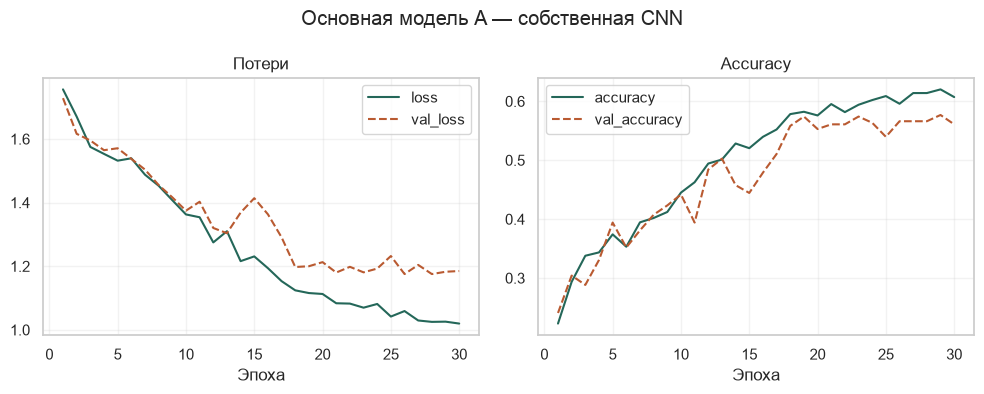

In [6]:
def augment(): return tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"),tf.keras.layers.RandomRotation(.08)])
def build_cnn(width=32,drop=.35,l2=1e-4,use_aug=True):
    reg=tf.keras.regularizers.l2(l2) if l2 else None; inp=tf.keras.Input((*IMG_SIZE,3)); x=inp
    if use_aug: x=augment()(x)
    x=tf.keras.layers.Rescaling(1/255.)(x)
    for f in (width,width*2,width*4): x=tf.keras.layers.MaxPooling2D()(tf.keras.layers.Conv2D(f,3,padding="same",activation="relu",kernel_regularizer=reg)(x))
    x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=reg)(x); x=tf.keras.layers.Dropout(drop)(x)
    x=tf.keras.layers.Dense(64,activation="relu",kernel_regularizer=reg)(x); out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x)
    m=tf.keras.Model(inp,out,name="custom_CNN"); m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m
cnn=build_cnn(); print("Модель A: Conv2D 32→64→128 → GAP → Dense128 → Dropout(.35) → Dense64 → Softmax(6); L2=1e-4; augmentation=flip/rotation"); cnn.summary()
h_cnn = train_model(cnn, train_ds, val_ds, "cnn", EPOCHS["cnn"])
curves(h_cnn,"Основная модель A — собственная CNN")
val_probs["CNN"]=cnn.predict(val_ds,verbose=0); results["CNN"]=score(Y_VAL,val_probs["CNN"])


## 6 Основная модель B — MobileNetV2 transfer learning
MobileNetV2 с ImageNet-весами используется как готовый извлекатель визуальных признаков. Свёрточная основа заморожена, обучается регуляризованная Dense-голова на шесть классов отходов. `preprocess_input` приводит пиксели к диапазону `[-1,1]`, ожидаемому сетью. Аугментация действует только на тренировочные примеры. На графиках оцениваем скорость обучения и переобучение.

Модель B: frozen MobileNetV2 ImageNet → GAP → Dense128(L2) → Dropout(.35) → Softmax(6); обучается только голова
Обучаемых параметров: 164742


Model: "MobileNetV2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (27 outputs left out)

Epoch 14/21


56/56 - 1s - 25ms/step - accuracy: 0.9541 - loss: 0.1854 - val_accuracy: 0.8069 - val_loss: 0.6286 - learning_rate: 5.0000e-04


Epoch 15/21


56/56 - 1s - 25ms/step - accuracy: 0.9518 - loss: 0.1782 - val_accuracy: 0.8148 - val_loss: 0.6369 - learning_rate: 5.0000e-04


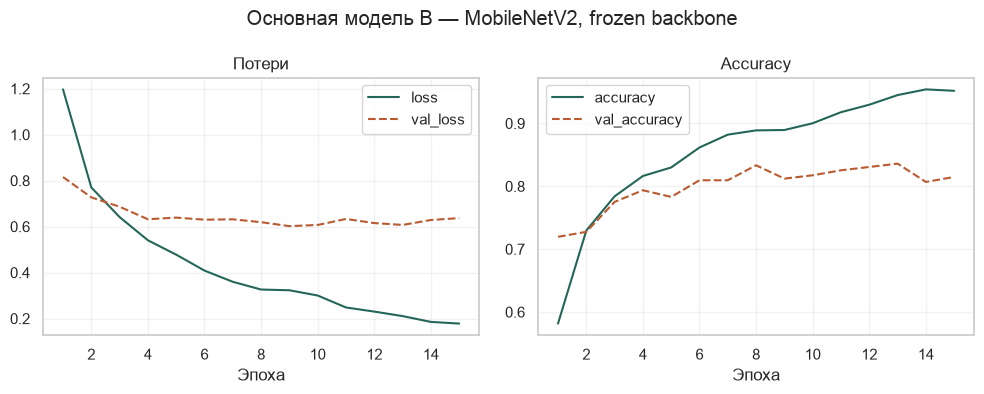

In [7]:
MOBILENET_WEIGHTS = DATA_DIR / "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_96_no_top.h5"

def build_mobile():
    weights = str(MOBILENET_WEIGHTS) if MOBILENET_WEIGHTS.is_file() else "imagenet"
    base=tf.keras.applications.MobileNetV2(include_top=False,weights=weights,input_shape=(*IMG_SIZE,3)); base.trainable=False
    inp=tf.keras.Input((*IMG_SIZE,3)); x=augment()(inp); x=tf.keras.applications.mobilenet_v2.preprocess_input(x); x=base(x,training=False)
    x=tf.keras.layers.GlobalAveragePooling2D()(x); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x); x=tf.keras.layers.Dropout(.35)(x)
    out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x); m=tf.keras.Model(inp,out,name="MobileNetV2_transfer")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m,base
mobile,mobile_base=build_mobile(); print("Модель B: frozen MobileNetV2 ImageNet → GAP → Dense128(L2) → Dropout(.35) → Softmax(6); обучается только голова"); print("Обучаемых параметров:",sum(np.prod(v.shape) for v in mobile.trainable_weights)); mobile.summary()
h_mobile = train_model(mobile, train_ds, val_ds, "mobile", EPOCHS["mobile"])
curves(h_mobile,"Основная модель B — MobileNetV2, frozen backbone")
val_probs["MobileNetV2 frozen"]=mobile.predict(val_ds,verbose=0); results["MobileNetV2 frozen"]=score(Y_VAL,val_probs["MobileNetV2 frozen"])


## 7 Классификатор на основе автоэнкодера

Используем общую схему предобучения и точной настройки из «Лекции 3», слайд 6, и softmax-классификатор со слайдов 64–67. Свёрточная архитектура адаптирована к RGB-фотографиям отходов.

Сначала автоэнкодер восстанавливает изображения train без меток, минимизируя MSE. Затем к энкодеру подключается Dense-голова с шестью выходами softmax. Голова обучается при замороженном энкодере. После этого весь энкодер размораживается и вместе с головой дообучается по правильным меткам с `sparse_categorical_crossentropy`. Декодер используется на этапе восстановления. Итоговая модель принимает фотографию и возвращает шесть вероятностей классов.

На validation сохраняются оценки до и после совместного дообучения. Такой опыт показывает, как изменяется классификация после адаптации признаков к меткам.


In [8]:
def build_ae(latent=64):
    inp=tf.keras.Input((*IMG_SIZE,3)); x=inp
    for f in (32,64,128): x=tf.keras.layers.Conv2D(f,3,strides=2,padding="same",activation="relu")(x)
    z=tf.keras.layers.Conv2D(latent,1,activation="relu",name="latent")(x); enc=tf.keras.Model(inp,z,name=f"encoder{latent}")
    zi=tf.keras.Input(tuple(z.shape[1:])); x=zi
    for f in (128,64,32): x=tf.keras.layers.Conv2DTranspose(f,3,strides=2,padding="same",activation="relu")(x)
    out=tf.keras.layers.Conv2D(3,3,padding="same",activation="sigmoid")(x); dec=tf.keras.Model(zi,out)
    ae=tf.keras.Model(inp,dec(enc(inp)),name=f"autoencoder{latent}"); ae.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="mse"); return enc,ae
def embed(enc,part):
    out=[]
    for x,_ in make_ds(part): out.append(enc(x/255.,training=False).numpy().reshape((x.shape[0],-1)))
    return np.concatenate(out)
def build_head(dim):
    inp=tf.keras.Input((dim,)); x=tf.keras.layers.Dense(128,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(1e-4))(inp); x=tf.keras.layers.Dropout(.35)(x)
    x=tf.keras.layers.Dense(64,activation="relu")(x); out=tf.keras.layers.Dense(NUM_CLASSES,activation="softmax")(x); m=tf.keras.Model(inp,out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="sparse_categorical_crossentropy",metrics=["accuracy"]); return m


### 7.1 Предобучение восстановлению изображения

Целевой ответ совпадает с входной фотографией. Для контроля показываем восстановление validation-фотографий до дообучения энкодера по меткам.

Автоэнкодер: три свёртки, скрытая карта 12 × 12 × 64, восстановление 96 × 96 × 3
Параметров: 268483
Epoch 1/18


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 6s - 98ms/step - loss: 0.0328 - val_loss: 0.0178 - learning_rate: 0.0010


Epoch 2/18


56/56 - 5s - 81ms/step - loss: 0.0158 - val_loss: 0.0140 - learning_rate: 0.0010


Epoch 3/18


... (27 outputs left out)

Epoch 17/18


56/56 - 5s - 82ms/step - loss: 0.0016 - val_loss: 0.0016 - learning_rate: 5.0000e-04


Epoch 18/18


56/56 - 5s - 82ms/step - loss: 0.0015 - val_loss: 0.0016 - learning_rate: 5.0000e-04


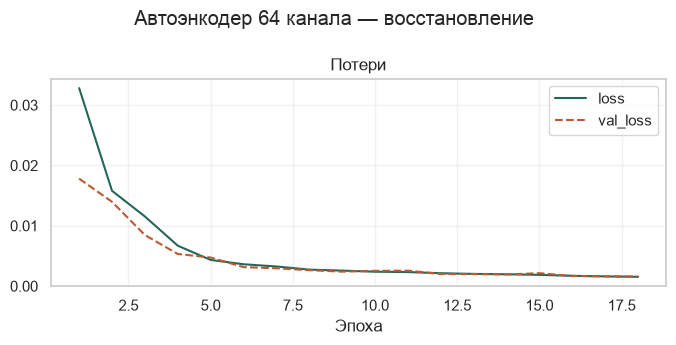

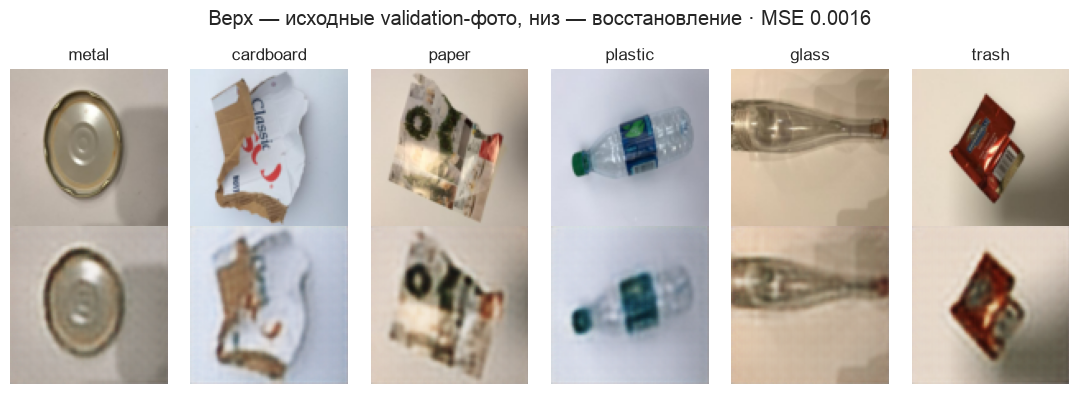

In [9]:
encoder, ae = build_ae(64)
print("Автоэнкодер: три свёртки, скрытая карта 12 × 12 × 64, восстановление 96 × 96 × 3")
print("Параметров:", ae.count_params())
h_ae = train_model(ae, ae_train_ds, ae_val_ds, "autoencoder64", EPOCHS["autoencoder"])
curves(h_ae, "Автоэнкодер 64 канала — восстановление")
reconstruction_mse = float(ae.evaluate(ae_val_ds, verbose=0))
example_rows = val_df.groupby("class", sort=False).head(1)
example_images = images[example_rows.image_id.to_numpy()].astype("float32") / 255.
reconstructed = ae.predict(example_images, verbose=0)
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(11, 4))
for i, class_name in enumerate(example_rows["class"]):
    axes[0, i].imshow(example_images[i]); axes[0, i].set_title(class_name)
    axes[1, i].imshow(reconstructed[i])
    axes[0, i].axis("off"); axes[1, i].axis("off")
fig.suptitle(f"Верх — исходные validation-фото, низ — восстановление · MSE {reconstruction_mse:.4f}")
plt.tight_layout(); plt.show()

### 7.2 Обучение классификационной головы

Энкодер пока заморожен. Обучение головы создаёт начальные веса выходной части перед совместной настройкой всей сети.

Epoch 1/54


56/56 - 1s - 10ms/step - accuracy: 0.2545 - loss: 1.9789 - val_accuracy: 0.3757 - val_loss: 1.6187 - learning_rate: 0.0010


Epoch 2/54


56/56 - 0s - 2ms/step - accuracy: 0.3458 - loss: 1.5923 - val_accuracy: 0.3598 - val_loss: 1.5813 - learning_rate: 0.0010


Epoch 3/54


56/56 - 0s - 2ms/step - accuracy: 0.3192 - loss: 1.6247 - val_accuracy: 0.3757 - val_loss: 1.6004 - learning_rate: 0.0010


... (96 outputs left out)

Epoch 52/54


56/56 - 0s - 2ms/step - accuracy: 0.4688 - loss: 1.2864 - val_accuracy: 0.4841 - val_loss: 1.3584 - learning_rate: 1.5625e-05


Epoch 53/54


56/56 - 0s - 2ms/step - accuracy: 0.4722 - loss: 1.2850 - val_accuracy: 0.4841 - val_loss: 1.3561 - learning_rate: 1.5625e-05


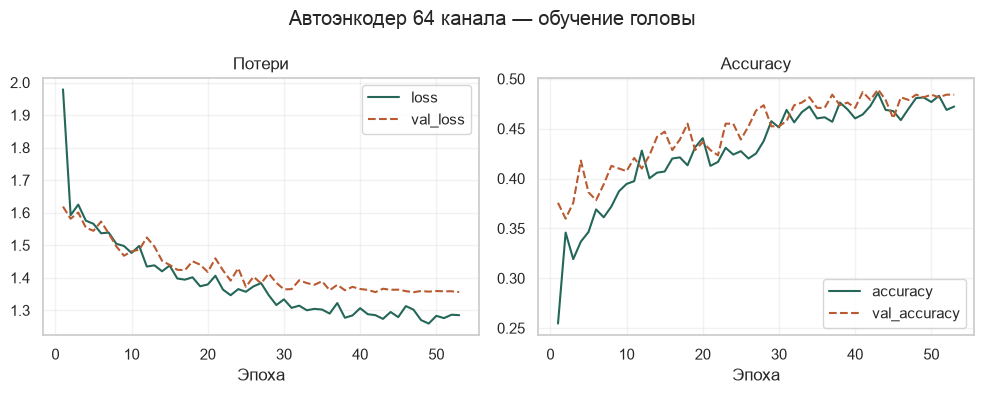

In [10]:
encoder.trainable = False
Xtr = embed(encoder, train_df)
Xva = embed(encoder, val_df)
head = build_head(Xtr.shape[1])
head_train_ds = tf.data.Dataset.from_tensor_slices((Xtr, train_df.label.to_numpy())).shuffle(len(train_df), seed=SEED).batch(BATCH_SIZE)
head_val_ds = tf.data.Dataset.from_tensor_slices((Xva, Y_VAL)).batch(BATCH_SIZE)
h_head = train_model(head, head_train_ds, head_val_ds, "ae64_head", EPOCHS["head"])
curves(h_head, "Автоэнкодер 64 канала — обучение головы")
val_probs["AE frozen"] = head.predict(Xva, verbose=0)
results["AE frozen"] = score(Y_VAL, val_probs["AE frozen"])

### 7.3 Совместное обучение энкодера и головы

В итоговый классификатор входят нормализация пикселей, энкодер, Flatten и обученная голова. Оптимизатор Adam с малым шагом обновляет веса энкодера и головы. Проверяем наличие градиента и изменение весов энкодера после обучения.

Выход классификатора: (None, 6)
Обучаемых параметров энкодера: 101504
Epoch 1/30


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 2s - 29ms/step - accuracy: 0.4615 - loss: 1.3327 - val_accuracy: 0.4735 - val_loss: 1.3534 - learning_rate: 1.0000e-04


Epoch 2/30


56/56 - 1s - 14ms/step - accuracy: 0.4813 - loss: 1.2900 - val_accuracy: 0.4815 - val_loss: 1.3452 - learning_rate: 1.0000e-04


Epoch 3/30


... (37 outputs left out)

Epoch 22/30


56/56 - 1s - 13ms/step - accuracy: 0.5085 - loss: 1.1967 - val_accuracy: 0.5053 - val_loss: 1.3085 - learning_rate: 2.5000e-05


Epoch 23/30


56/56 - 1s - 14ms/step - accuracy: 0.4926 - loss: 1.2010 - val_accuracy: 0.5132 - val_loss: 1.3038 - learning_rate: 2.5000e-05


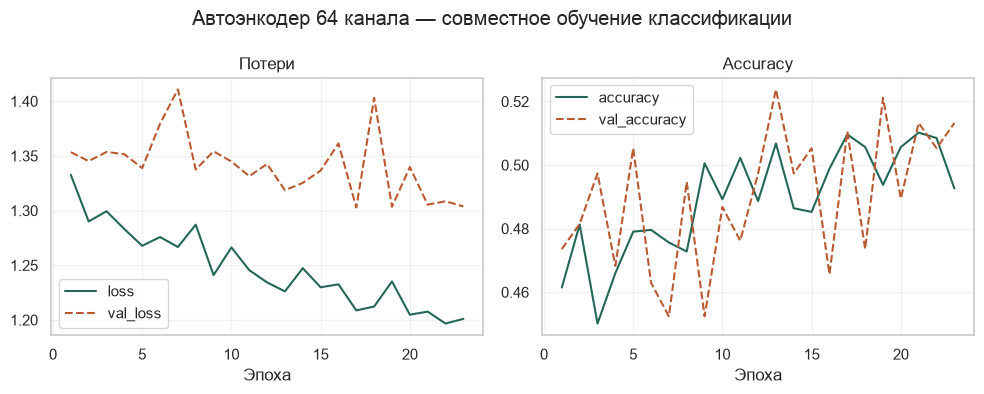

,accuracy,macro_f1,cross_entropy
AE frozen,0.478836,0.399454,1.343068
AE classifier,0.510582,0.423267,1.296885


In [11]:
def build_ae_classifier(enc, trained_head, name):
    enc.trainable = True
    inp = tf.keras.Input((*IMG_SIZE, 3))
    x = tf.keras.layers.Rescaling(1 / 255.)(inp)
    x = enc(x)
    x = tf.keras.layers.Flatten()(x)
    model = tf.keras.Model(inp, trained_head(x), name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-4),
        loss="sparse_categorical_crossentropy", metrics=["accuracy"],
    )
    return model

classifier = build_ae_classifier(encoder, head, "AE64_classifier")
encoder_weights_before = [v.numpy().copy() for v in encoder.trainable_weights]
check_x, check_y = next(iter(train_ds))
with tf.GradientTape() as tape:
    check_probs = classifier(check_x, training=True)
    check_loss = tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(check_y, check_probs))
encoder_grads = tape.gradient(check_loss, encoder.trainable_weights)
assert encoder_grads and all(g is not None for g in encoder_grads)
assert all(bool(tf.reduce_all(tf.math.is_finite(g))) for g in encoder_grads)
assert any(bool(tf.reduce_any(tf.not_equal(g, 0))) for g in encoder_grads)
print("Выход классификатора:", classifier.output_shape)
print("Обучаемых параметров энкодера:", sum(np.prod(v.shape) for v in encoder.trainable_weights))
h_classifier = train_model(classifier, train_ds, val_ds, "ae64_classifier", EPOCHS["ae_finetune"])
assert any(not np.array_equal(before, after.numpy()) for before, after in zip(encoder_weights_before, encoder.trainable_weights))
curves(h_classifier, "Автоэнкодер 64 канала — совместное обучение классификации")
val_probs["AE classifier"] = classifier.predict(val_ds, verbose=0)
results["AE classifier"] = score(Y_VAL, val_probs["AE classifier"])
display(pd.DataFrame({name: results[name] for name in ("AE frozen", "AE classifier")}).T[["accuracy", "macro_f1", "cross_entropy"]])

## 8 Опыт E1 — более узкая CNN без аугментации и регуляризации

Сравниваем с основной CNN. Одновременно меняются аугментация, Dropout, L2, ширина и лимит эпох, поэтому нельзя приписать разницу одному фактору.

Опыт E1: Conv2D 24→48→96 → GAP → Dense128 → Dense64 → Softmax; augmentation OFF, dropout OFF, L2 OFF; максимум 15 эпох
Epoch 1/15


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 3s - 50ms/step - accuracy: 0.2251 - loss: 1.7318 - val_accuracy: 0.1984 - val_loss: 1.7125 - learning_rate: 0.0010


Epoch 2/15


56/56 - 2s - 35ms/step - accuracy: 0.2761 - loss: 1.6633 - val_accuracy: 0.3280 - val_loss: 1.5670 - learning_rate: 0.0010


Epoch 3/15


... (21 outputs left out)

Epoch 14/15


56/56 - 2s - 35ms/step - accuracy: 0.5998 - loss: 1.0649 - val_accuracy: 0.5503 - val_loss: 1.2258 - learning_rate: 0.0010


Epoch 15/15


56/56 - 2s - 35ms/step - accuracy: 0.6037 - loss: 1.0099 - val_accuracy: 0.5212 - val_loss: 1.3003 - learning_rate: 0.0010


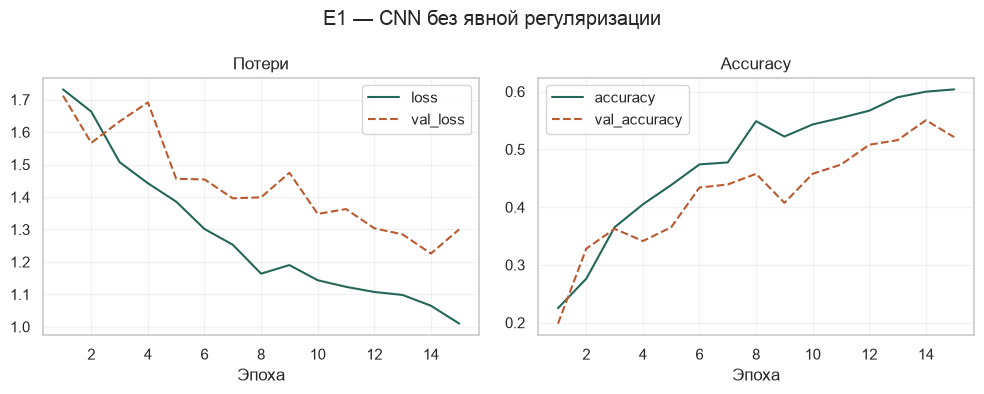

In [12]:
cnn_plain=build_cnn(width=24,drop=0,l2=0,use_aug=False)
print(f"Опыт E1: Conv2D 24→48→96 → GAP → Dense128 → Dense64 → Softmax; augmentation OFF, dropout OFF, L2 OFF; максимум {5 * EPOCH_MULTIPLIER} эпох")
h_plain = train_model(cnn_plain, train_ds, val_ds, "cnn_plain", EPOCHS["cnn_plain"])
curves(h_plain,"E1 — CNN без явной регуляризации"); val_probs["CNN no regularization"]=cnn_plain.predict(val_ds,verbose=0); results["CNN no regularization"]=score(Y_VAL,val_probs["CNN no regularization"])


## 9 Расширенный эксперимент 2 — частичный fine-tuning MobileNetV2
Копируем исходно обученную MobileNetV2, размораживаем только последние 20 слоёв и используем малый learning rate `1e-5`. BatchNormalization остаётся замороженной, ранние слои не изменяются. Это проверяет, улучшает ли ограниченная адаптация ImageNet-фильтров качество на фотографиях отходов. Сравниваем validation macro-F1 и кривые.

Опыт E2: MobileNetV2 последние 20 слоёв trainable, BatchNorm frozen; Dense head; Adam=1e-5; максимум 12 эпох; trainable params: 1359622
Epoch 1/12


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 4s - 79ms/step - accuracy: 0.9178 - loss: 0.2603 - val_accuracy: 0.8307 - val_loss: 0.5938 - learning_rate: 1.0000e-05


Epoch 2/12


56/56 - 2s - 31ms/step - accuracy: 0.9337 - loss: 0.2243 - val_accuracy: 0.8280 - val_loss: 0.6094 - learning_rate: 1.0000e-05


Epoch 3/12


... (13 outputs left out)

Epoch 10/12


56/56 - 2s - 31ms/step - accuracy: 0.9609 - loss: 0.1445 - val_accuracy: 0.8360 - val_loss: 0.5988 - learning_rate: 2.5000e-06


Epoch 11/12


56/56 - 2s - 31ms/step - accuracy: 0.9535 - loss: 0.1689 - val_accuracy: 0.8333 - val_loss: 0.5926 - learning_rate: 2.5000e-06


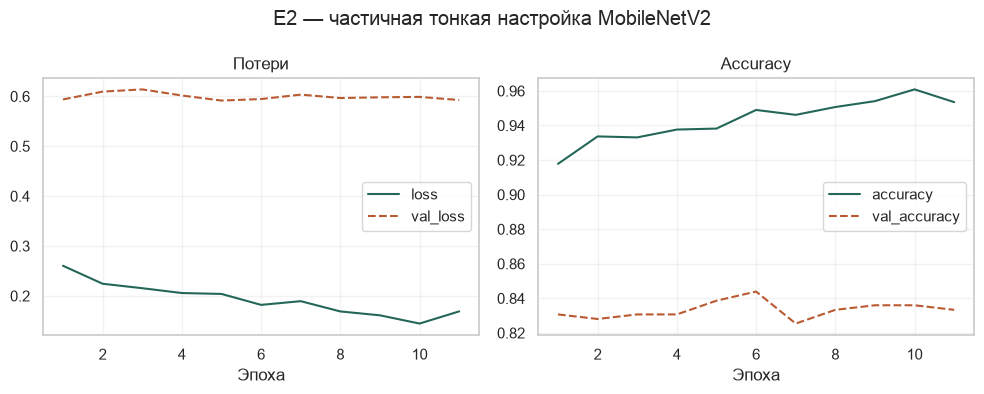

In [13]:
mobile_ft,base_ft=build_mobile(); mobile_ft.set_weights(mobile.get_weights()); base_ft.trainable=True
for layer in base_ft.layers[:-20]: layer.trainable=False
for layer in base_ft.layers:
    if isinstance(layer,tf.keras.layers.BatchNormalization): layer.trainable=False
mobile_ft.compile(optimizer=tf.keras.optimizers.Adam(1e-5),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
print(f"Опыт E2: MobileNetV2 последние 20 слоёв trainable, BatchNorm frozen; Dense head; Adam=1e-5; максимум {4 * EPOCH_MULTIPLIER} эпох; trainable params:",sum(np.prod(v.shape) for v in mobile_ft.trainable_weights))
h_ft = train_model(mobile_ft, train_ds, val_ds, "mobile_finetune", EPOCHS["mobile_finetune"])
curves(h_ft,"E2 — частичная тонкая настройка MobileNetV2"); val_probs["MobileNetV2 fine-tuned"]=mobile_ft.predict(val_ds,verbose=0); results["MobileNetV2 fine-tuned"]=score(Y_VAL,val_probs["MobileNetV2 fine-tuned"])


## 10 Компактное скрытое представление

Повторяем предобучение, обучение головы и совместную настройку с 32 скрытыми каналами. Лимиты эпох, шаг обучения и разбиение совпадают с моделью на 64 канала. Меняются размер скрытой карты и число входных признаков головы.


Epoch 1/18


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 5s - 96ms/step - loss: 0.0342 - val_loss: 0.0175 - learning_rate: 0.0010


Epoch 2/18


56/56 - 4s - 79ms/step - loss: 0.0164 - val_loss: 0.0152 - learning_rate: 0.0010


Epoch 3/18


... (27 outputs left out)

Epoch 17/18


56/56 - 4s - 79ms/step - loss: 0.0019 - val_loss: 0.0019 - learning_rate: 0.0010


Epoch 18/18


56/56 - 4s - 79ms/step - loss: 0.0020 - val_loss: 0.0029 - learning_rate: 0.0010


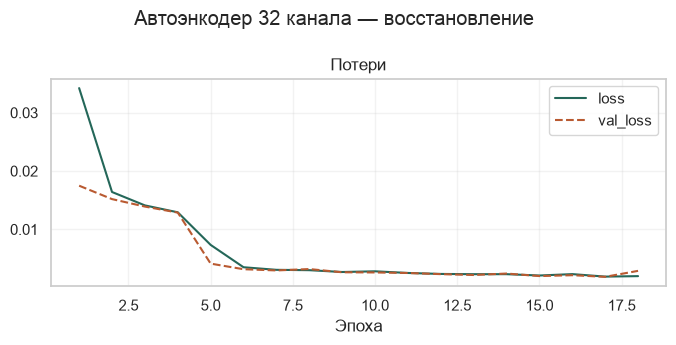

Epoch 1/54


56/56 - 1s - 12ms/step - accuracy: 0.2613 - loss: 1.8101 - val_accuracy: 0.3386 - val_loss: 1.6246 - learning_rate: 0.0010


Epoch 2/54


56/56 - 0s - 1ms/step - accuracy: 0.3135 - loss: 1.6250 - val_accuracy: 0.3122 - val_loss: 1.6216 - learning_rate: 0.0010


Epoch 3/54


56/56 - 0s - 1ms/step - accuracy: 0.3747 - loss: 1.5583 - val_accuracy: 0.4021 - val_loss: 1.5219 - learning_rate: 0.0010


... (70 outputs left out)

Epoch 39/54


56/56 - 0s - 1ms/step - accuracy: 0.5584 - loss: 1.1028 - val_accuracy: 0.5370 - val_loss: 1.2491 - learning_rate: 3.1250e-05


Epoch 40/54


56/56 - 0s - 1ms/step - accuracy: 0.5646 - loss: 1.0961 - val_accuracy: 0.5291 - val_loss: 1.2482 - learning_rate: 3.1250e-05


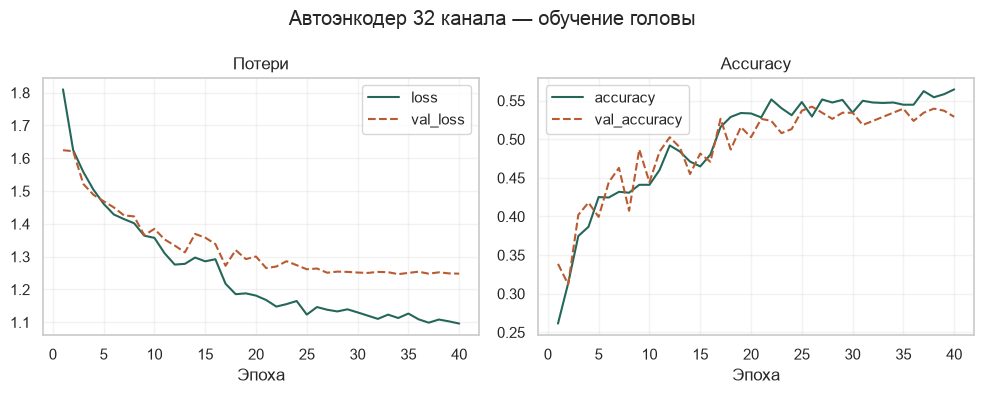

Epoch 1/30


/Users/svyathorse/Yandex.Disk.localized/SUAI GUAP/4 Курс/Скобцов - сын/tmp/lr3_kaggle/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


56/56 - 2s - 29ms/step - accuracy: 0.5522 - loss: 1.1340 - val_accuracy: 0.5238 - val_loss: 1.2452 - learning_rate: 1.0000e-04


Epoch 2/30


56/56 - 1s - 13ms/step - accuracy: 0.5510 - loss: 1.1112 - val_accuracy: 0.5291 - val_loss: 1.2485 - learning_rate: 1.0000e-04


Epoch 3/30


... (31 outputs left out)

Epoch 19/30


56/56 - 1s - 13ms/step - accuracy: 0.5839 - loss: 1.0522 - val_accuracy: 0.5423 - val_loss: 1.2132 - learning_rate: 1.2500e-05


Epoch 20/30


56/56 - 1s - 13ms/step - accuracy: 0.5635 - loss: 1.0700 - val_accuracy: 0.5370 - val_loss: 1.2203 - learning_rate: 1.2500e-05


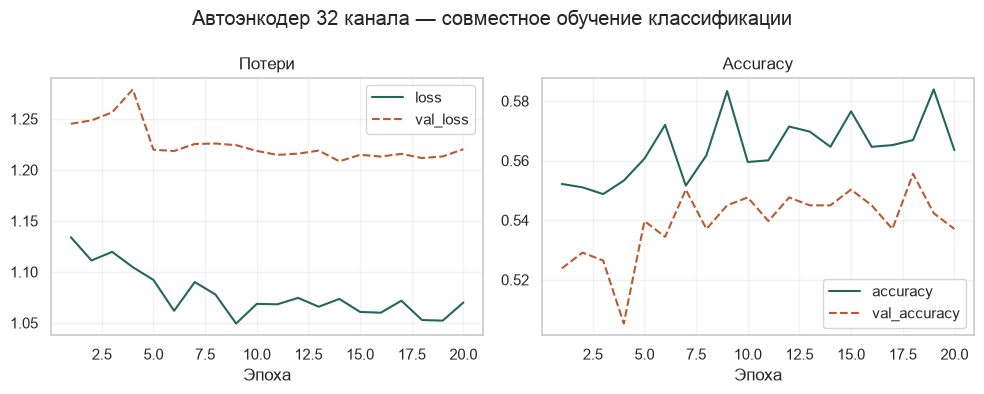

In [14]:
enc32, ae32 = build_ae(32)
h_ae32 = train_model(ae32, ae_train_ds, ae_val_ds, "autoencoder32", EPOCHS["autoencoder"])
curves(h_ae32, "Автоэнкодер 32 канала — восстановление")
enc32.trainable = False
Xtr32 = embed(enc32, train_df)
Xva32 = embed(enc32, val_df)
head32 = build_head(Xtr32.shape[1])
head32_train_ds = tf.data.Dataset.from_tensor_slices((Xtr32, train_df.label.to_numpy())).shuffle(len(train_df), seed=SEED).batch(BATCH_SIZE)
head32_val_ds = tf.data.Dataset.from_tensor_slices((Xva32, Y_VAL)).batch(BATCH_SIZE)
h_head32 = train_model(head32, head32_train_ds, head32_val_ds, "ae32_head", EPOCHS["head"])
curves(h_head32, "Автоэнкодер 32 канала — обучение головы")
val_probs["AE32 frozen"] = head32.predict(Xva32, verbose=0)
results["AE32 frozen"] = score(Y_VAL, val_probs["AE32 frozen"])
classifier32 = build_ae_classifier(enc32, head32, "AE32_classifier")
h_classifier32 = train_model(classifier32, train_ds, val_ds, "ae32_classifier", EPOCHS["ae_finetune"])
curves(h_classifier32, "Автоэнкодер 32 канала — совместное обучение классификации")
val_probs["AE32 classifier"] = classifier32.predict(val_ds, verbose=0)
results["AE32 classifier"] = score(Y_VAL, val_probs["AE32 classifier"])


## 11 Сводка экспериментов на validation
Validation используется для сравнения, но test остаётся нетронутым. Macro-F1 и balanced accuracy усредняются по классам; cross-entropy учитывает уверенность прогнозов. Значения ниже помогают интерпретировать влияние аугментации, transfer learning и размерности embeddings.

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,cross_entropy
MobileNetV2 fine-tuned,0.839,0.820,0.835,0.820,0.826,0.565
MobileNetV2 frozen,0.812,0.791,0.796,0.791,0.790,0.575
CNN,0.566,0.488,0.478,0.488,0.475,1.153
CNN no regularization,0.550,0.476,0.478,0.476,0.469,1.226
AE32 classifier,0.545,0.468,0.473,0.468,0.459,1.199
AE32 frozen,0.534,0.457,0.454,0.457,0.447,1.233
AE classifier,0.511,0.432,0.452,0.432,0.423,1.297
AE frozen,0.479,0.406,0.418,0.406,0.399,1.343


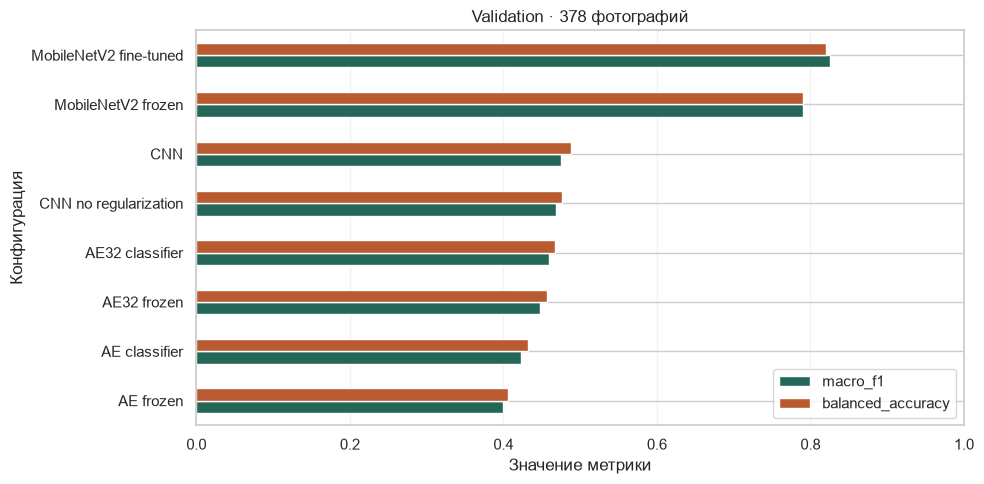

Фактические эпохи и лучшие контрольные точки


,stage,limit,completed,best_epoch,best_val_loss,seconds
0,cnn,30,30,28,1.175,87.94
1,mobile,21,15,9,0.602,24.05
2,autoencoder64,18,18,18,0.002,83.34
3,ae64_head,54,53,47,1.356,5.36
4,ae64_classifier,30,23,17,1.303,18.29
5,cnn_plain,15,15,14,1.226,30.25
6,mobile_finetune,12,11,5,0.591,22.33
7,autoencoder32,18,18,17,0.002,81.31
8,ae32_head,54,40,34,1.247,3.20
9,ae32_classifier,30,20,14,1.208,15.31


In [15]:
val_table = pd.DataFrame(results).T.sort_values("macro_f1", ascending=False)
display(val_table[["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "cross_entropy"]].round(3))
ax = val_table[["macro_f1", "balanced_accuracy"]].sort_values("macro_f1").plot(
    kind="barh", figsize=(10, 5), xlim=(0, 1),
    title=f"Validation · {len(val_df)} фотографий", color=["#246759", "#b95a31"],
)
ax.set_xlabel("Значение метрики"); ax.set_ylabel("Конфигурация")
ax.grid(axis="x", alpha=.25); plt.tight_layout(); plt.show()
print("Фактические эпохи и лучшие контрольные точки")
display(pd.DataFrame(training_runs).round(3))


## 12 Финальная проверка на test

После обучения оцениваем три основные модели на 379 test-фотографиях. Третья модель — целиком дообученный классификатор на основе автоэнкодера. Дополнительные конфигурации сравниваются по validation. Test используется для итогового описания качества.


,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,cross_entropy
CNN,0.594,0.517,0.680,0.517,0.515,1.025
MobileNetV2 frozen,0.805,0.762,0.797,0.762,0.771,0.561
AE classifier,0.536,0.460,0.483,0.460,0.453,1.216


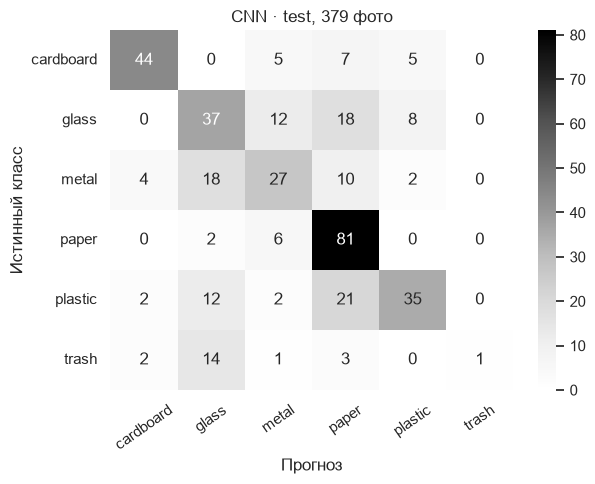

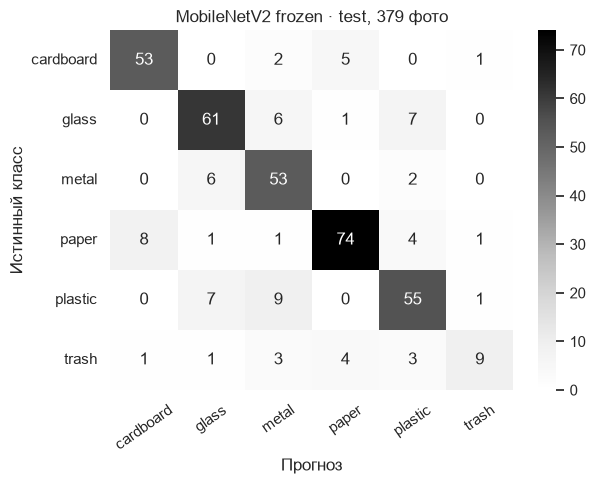

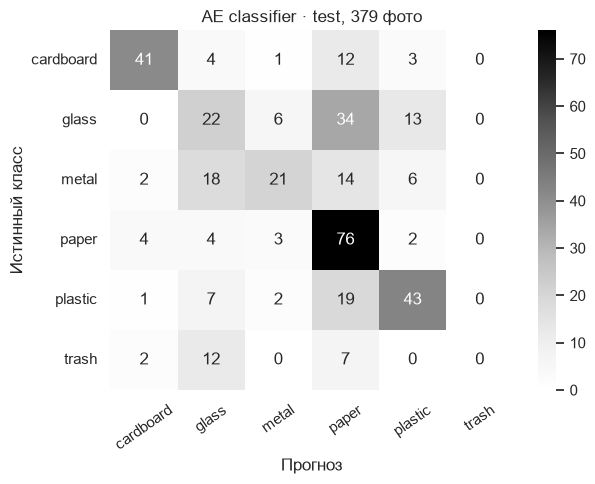

Отчёт по классификатору на основе автоэнкодера
              precision    recall  f1-score   support

   cardboard       0.82      0.67      0.74        61
       glass       0.33      0.29      0.31        75
       metal       0.64      0.34      0.45        61
       paper       0.47      0.85      0.61        89
     plastic       0.64      0.60      0.62        72
       trash       0.00      0.00      0.00        21

    accuracy                           0.54       379
   macro avg       0.48      0.46      0.45       379
weighted avg       0.53      0.54      0.51       379



In [16]:
test_ds = make_ds(test_df)
Y_TEST = test_df.label.to_numpy()
core = {"CNN": cnn, "MobileNetV2 frozen": mobile, "AE classifier": classifier}
for name, model in core.items():
    test_probs[name] = model.predict(test_ds, verbose=0)
test_table = pd.DataFrame({name: score(Y_TEST, probs) for name, probs in test_probs.items()}).T
display(test_table[["accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "macro_f1", "cross_entropy"]].round(3))
for name, probs in test_probs.items():
    cm = confusion_matrix(Y_TEST, probs.argmax(axis=1), labels=np.arange(NUM_CLASSES))
    assert cm.sum() == len(test_df)
    fig, ax = plt.subplots(figsize=(6.4, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greys", vmin=0,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name} · test, {len(test_df)} фото")
    ax.set_xlabel("Прогноз"); ax.set_ylabel("Истинный класс")
    ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
    plt.tight_layout(); plt.show()
print("Отчёт по классификатору на основе автоэнкодера")
print(classification_report(Y_TEST, test_probs["AE classifier"].argmax(axis=1), target_names=class_names, zero_division=0))


## 13 Итоговый вывод по лабораторной работе
Заключение формируется по измеренным метрикам ниже, а не заранее заданным ожиданиям.

In [17]:
best_val = val_table.index[0]
best_test = test_table.macro_f1.idxmax()
summary = (
    f"На test из {len(test_df)} фото наибольший macro-F1 среди трёх основных моделей "
    f"у {best_test}: {test_table.loc[best_test, 'macro_f1']:.3f}, "
    f"accuracy {test_table.loc[best_test, 'accuracy']:.1%}. "
    f"На validation среди всех конфигураций лидирует {best_val}: "
    f"macro-F1 {val_table.loc[best_val, 'macro_f1']:.3f}."
)
ae_delta = results["AE classifier"]["macro_f1"] - results["AE frozen"]["macro_f1"]
display(Markdown("### Выводы по выполненному запуску\n\n" + summary + "\n\n" +
    f"После совместной настройки энкодера и головы validation macro-F1 изменился "
    f"с {results['AE frozen']['macro_f1']:.3f} до {results['AE classifier']['macro_f1']:.3f} "
    f"(разность {ae_delta:+.3f}). Выход итоговой модели — шесть вероятностей классов. "
    "Качество определяется по меткам фотографий. Ошибка восстановления относится к этапу предобучения. "
    "Сравнение выполнено на одном разбиении с seed 42."))
metrics = {
    "started_utc": RUN_STARTED, "finished_utc": datetime.now(timezone.utc).isoformat(),
    "elapsed_seconds": time.perf_counter() - RUN_TIMER,
    "python": sys.version.split()[0], "tensorflow": tf.__version__,
    "devices": [d.device_type for d in tf.config.list_physical_devices()],
    "seed": SEED, "epoch_multiplier": EPOCH_MULTIPLIER, "epoch_limits": EPOCHS,
    "audit": audit, "splits": {k: len(v) for k, v in parts.items()},
    "class_counts": {k: int(v) for k, v in counts.items()},
    "validation": results,
    "test": {name: score(Y_TEST, p) for name, p in test_probs.items()},
    "training": training_runs, "pretraining_validation_mse": reconstruction_mse,
    "ae_validation_f1_change": ae_delta,
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2))
val_table.to_csv(ARTIFACTS / "validation.csv")
test_table.to_csv(ARTIFACTS / "test.csv")
pd.DataFrame(training_runs).to_csv(ARTIFACTS / "training_epochs.csv", index=False)
np.savez_compressed(ARTIFACTS / "test_predictions.npz", y_true=Y_TEST, **test_probs)
classifier.save(ARTIFACTS / "ae64_classifier.keras")
print("Метрики, истории, прогнозы и классификатор сохранены в", ARTIFACTS)


### Выводы по выполненному запуску

На test из 379 фото наибольший macro-F1 среди трёх основных моделей у MobileNetV2 frozen: 0.771, accuracy 80.5%. На validation среди всех конфигураций лидирует MobileNetV2 fine-tuned: macro-F1 0.826.

После совместной настройки энкодера и головы validation macro-F1 изменился с 0.399 до 0.423 (разность +0.024). Выход итоговой модели — шесть вероятностей классов. Качество определяется по меткам фотографий. Ошибка восстановления относится к этапу предобучения. Сравнение выполнено на одном разбиении с seed 42.

Метрики, истории, прогнозы и классификатор сохранены в lr3/results


## Интерпретация результатов

Совместная настройка энкодера и головы увеличила validation macro-F1 с 0,399 до 0,423. На test классификатор на основе автоэнкодера получил accuracy 53,6% и macro-F1 0,453. В этой конфигурации 21 test-фотография класса trash дали F1, равный 0. В train у этого класса 95 фотографий, поэтому для оценки важны метрики каждого класса и macro-F1.

MobileNetV2 использует признаки, ранее выученные на ImageNet, и на этом разбиении показала accuracy 80,5% и macro-F1 0,771. У автоэнкодера предобучение направлено на восстановление цвета, формы и фона. Затем классификационное дообучение адаптирует признаки к меткам отходов. Этим различием целей можно объяснять наблюдаемую разницу качества как одну из гипотез.

Увеличенные лимиты дали собственной CNN 30 эпох, предобучению автоэнкодера 18 эпох, голове 53 эпохи из 54 и совместной настройке 23 эпохи из 30. Лучшие веса совместной настройки выбраны по validation loss на 17-й эпохе. Дополнительные эпохи после этой точки использовались для проверки улучшения и работы ранней остановки.
